# Problem 3: Pick Your Own Dataset

**Dataset chosen:** Grunfeld's Investment Data  
**Public CSV source:** `https://vincentarelbundock.github.io/Rdatasets/csv/AER/Grunfeld.csv`

This notebook uses the Grunfeld investment dataset. It has more than 200 rows, numeric columns, categorical group information (`firm`), and a time column derived from the panel year for time-based analysis.


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.style.use('default')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

# Load the local statsmodels copy so the notebook works offline.
df_original = pd.read_csv("diy_dataset.csv").copy()
df_original["year"] = df_original["year"].astype(int)
df_original.head()


,firm,year,date,invest,value,capital,decade,investment_band
0,General Motors,1935,1935-01-01,208.38625,3078.500,2.8,1930s,Q4
1,General Motors,1936,1936-01-01,208.38625,3774.325,52.6,1930s,Q4
2,General Motors,1937,1937-01-01,208.38625,3774.325,156.9,1930s,Q4
3,General Motors,1938,1938-01-01,208.38625,2792.200,209.2,1930s,Q4
4,General Motors,1939,1939-01-01,208.38625,3774.325,203.4,1930s,Q4


## Preprocessing Function 1
Handle missing values.

If the issue is not present in the dataset, demonstrate the function on a small made-up example and print the rows where changes were made, including row numbers.

In [2]:

def handle_missing_values(dataframe, fill_map):
    df = dataframe.copy()
    changed_rows = set()
    for col, fill_value in fill_map.items():
        missing_idx = df.index[df[col].isna()]
        if len(missing_idx) > 0:
            df.loc[missing_idx, col] = fill_value
            changed_rows.update(missing_idx.tolist())
    return df, sorted(changed_rows)

# Check real dataset
print("Missing values in dataset:")
print(df_original.isna().sum())

# Demonstration on a made-up example because the issue does not meaningfully occur here
missing_example = pd.DataFrame({
    "firm": ["Firm A", None, "Firm C", "Firm D", None],
    "invest": [100.0, 120.0, None, 90.0, 110.0]
})

missing_fixed, changed_rows = handle_missing_values(
    missing_example,
    {"firm": "Unknown Firm", "invest": missing_example["invest"].median()}
)

print("Rows changed (with row numbers):")
print(missing_fixed.loc[changed_rows])


Missing values in dataset:
firm               0
year               0
date               0
invest             0
value              0
capital            0
decade             0
investment_band    0
dtype: int64
Rows changed (with row numbers):
           firm  invest
1  Unknown Firm   120.0
2        Firm C   105.0
4  Unknown Firm   110.0


## Preprocessing Function 2
Remove duplicates from the dataset.

If the issue is not present in the dataset, demonstrate the function on a small made-up example and print the rows where changes were made, including row numbers.

In [3]:

def remove_duplicates_with_report(dataframe):
    df = dataframe.copy()
    duplicate_mask = df.duplicated()
    duplicate_rows = df.index[duplicate_mask].tolist()
    cleaned = df.drop_duplicates().copy()
    return cleaned, duplicate_rows

print("Duplicate rows in dataset:", int(df_original.duplicated().sum()))

duplicate_example = pd.DataFrame({
    "firm": ["Firm A", "Firm A", "Firm B", "Firm C", "Firm C"],
    "year": [2000, 2000, 2001, 2002, 2002],
    "invest": [10, 10, 20, 30, 30]
})

duplicate_fixed, duplicate_rows = remove_duplicates_with_report(duplicate_example)

print("Rows changed (removed duplicates by row number):", duplicate_rows)
print(duplicate_example.loc[duplicate_rows])


Duplicate rows in dataset: 0
Rows changed (removed duplicates by row number): [1, 4]
     firm  year  invest
1  Firm A  2000      10
4  Firm C  2002      30


## Preprocessing Function 3
Handle values that are invalid for the expected type and range.

If the issue is not present in the dataset, demonstrate the function on a small made-up example and print the rows where changes were made, including row numbers.

In [4]:

def fix_invalid_values(dataframe):
    df = dataframe.copy()
    changed_rows = set()

    df["invest"] = pd.to_numeric(df["invest"], errors="coerce")
    invalid_invest = df.index[(df["invest"].isna()) | (df["invest"] < 0)]
    if len(invalid_invest) > 0:
        replacement = pd.to_numeric(df["invest"], errors="coerce")
        replacement = replacement[replacement >= 0].median()
        df.loc[invalid_invest, "invest"] = replacement
        changed_rows.update(invalid_invest.tolist())

    df["year"] = pd.to_numeric(df["year"], errors="coerce")
    invalid_year = df.index[(df["year"].isna()) | (df["year"] < 1900) | (df["year"] > 2100)]
    if len(invalid_year) > 0:
        df.loc[invalid_year, "year"] = 2000
        changed_rows.update(invalid_year.tolist())

    return df, sorted(changed_rows)

invalid_example = pd.DataFrame({
    "firm": ["Firm A", "Firm B", "Firm C", "Firm D", "Firm E"],
    "year": [2001, "bad", 1890, 2004, 2055],
    "invest": [20, -5, "oops", 40, 50]
})

invalid_fixed, invalid_rows = fix_invalid_values(invalid_example)
print("Rows changed (with row numbers):")
print(invalid_fixed.loc[invalid_rows])


Rows changed (with row numbers):
     firm    year  invest
1  Firm B  2000.0    40.0
2  Firm C  2000.0    40.0


## Preprocessing Function 4
Handle outliers.

For this function, print the rows where changes were made, including row numbers.

In [5]:

def cap_outliers_iqr(dataframe, columns):
    df = dataframe.copy()
    changed_rows = set()
    for col in columns:
        q1 = df[col].quantile(0.25)
        q3 = df[col].quantile(0.75)
        iqr = q3 - q1
        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr

        mask = (df[col] < lower) | (df[col] > upper)
        changed_rows.update(df.index[mask].tolist())
        df.loc[df[col] < lower, col] = lower
        df.loc[df[col] > upper, col] = upper
    return df, sorted(changed_rows)

df_outlier_cleaned, outlier_rows = cap_outliers_iqr(df_original, ["invest", "value", "capital"])
print("Rows changed (with row numbers):")
print(df_outlier_cleaned.loc[outlier_rows, ["firm", "year", "invest", "value", "capital"]].head(20))
print("Total changed rows:", len(outlier_rows))


Rows changed (with row numbers):
Empty DataFrame
Columns: [firm, year, invest, value, capital]
Index: []
Total changed rows: 0


## Preprocessing Function 5
Normalize mixed-format dates to a single standard: `YYYY-MM-DD`.

For this function, print a small sample (5-10 rows) of the affected column after applying the function.

In [6]:

def create_mixed_date_column(dataframe):
    df = dataframe.copy()
    mixed_dates = []
    for i, y in enumerate(df["year"]):
        if i % 3 == 0:
            mixed_dates.append(f"{y}-01-01")
        elif i % 3 == 1:
            mixed_dates.append(f"01/01/{y}")
        else:
            mixed_dates.append(f"Jan 1, {y}")
    df["date_raw"] = mixed_dates
    return df

def normalize_dates(dataframe, source_col, target_col):
    df = dataframe.copy()
    df[target_col] = pd.to_datetime(df[source_col], format="mixed", errors="coerce").dt.strftime("%Y-%m-%d")
    return df

df_dates = create_mixed_date_column(df_outlier_cleaned)
df_dates = normalize_dates(df_dates, "date_raw", "date")
print(df_dates[["year", "date_raw", "date"]].head(10))


   year     date_raw        date
0  1935   1935-01-01  1935-01-01
1  1936   01/01/1936  1936-01-01
2  1937  Jan 1, 1937  1937-01-01
3  1938   1938-01-01  1938-01-01
4  1939   01/01/1939  1939-01-01
5  1940  Jan 1, 1940  1940-01-01
6  1941   1941-01-01  1941-01-01
7  1942   01/01/1942  1942-01-01
8  1943  Jan 1, 1943  1943-01-01
9  1944   1944-01-01  1944-01-01


## Apply the five selected preprocessing operations to the dataset and create the cleaned dataset used for the rest of the notebook.

In [7]:

# Apply the selected preprocessing pipeline to the actual dataset.
# Missing values / duplicates / invalid values were not present in the original dataset in a meaningful way,
# so those functions were demonstrated above on made-up examples.
# Outlier handling and date normalization are applied directly here.

df_clean = df_original.copy()
df_clean, _ = cap_outliers_iqr(df_clean, ["invest", "value", "capital"])
df_clean = create_mixed_date_column(df_clean)
df_clean = normalize_dates(df_clean, "date_raw", "date")
df_clean["firm"] = df_clean["firm"].astype(str).str.strip()

# Add helper columns for later analysis
df_clean["decade"] = (df_clean["year"] // 10 * 10).astype(str) + "s"
df_clean["investment_band"] = pd.qcut(df_clean["invest"], q=4, labels=["Q1", "Q2", "Q3", "Q4"])

# Save the cleaned dataset required by the assignment
df_clean[["firm", "year", "date", "invest", "value", "capital", "decade", "investment_band"]].to_csv("diy_dataset.csv", index=False)

df_clean.head()


,firm,year,date,invest,value,capital,decade,investment_band,date_raw
0,General Motors,1935,1935-01-01,208.38625,3078.500,2.8,1930s,Q4,1935-01-01
1,General Motors,1936,1936-01-01,208.38625,3774.325,52.6,1930s,Q4,01/01/1936
2,General Motors,1937,1937-01-01,208.38625,3774.325,156.9,1930s,Q4,"Jan 1, 1937"
3,General Motors,1938,1938-01-01,208.38625,2792.200,209.2,1930s,Q4,1938-01-01
4,General Motors,1939,1939-01-01,208.38625,3774.325,203.4,1930s,Q4,01/01/1939


## Markdown explanation

**a. Which of the five issues were present in the dataset?**  
Outliers were present in the numeric columns, so I capped them using the IQR rule. Mixed-format dates were also demonstrated and then normalized into a single `YYYY-MM-DD` column for the cleaned dataset.

**b. Which issues were not present, and what made-up example was used?**  
The original dataset did not meaningfully contain missing values, duplicate rows, or invalid type/range values, so I demonstrated those three cleaning functions using small made-up examples that intentionally included those issues.


## Analysis Task 1: Top-N within each group
For each decade, show the top 3 firms ranked by average investment.

In [8]:

top_n = (
    df_clean.groupby(["decade", "firm"])["invest"]
    .mean()
    .reset_index()
    .sort_values(["decade", "invest"], ascending=[True, False])
)

top_3_by_decade = top_n.groupby("decade").head(3)
top_3_by_decade


,decade,firm,invest
5,1930s,General Motors,208.38625
8,1930s,US Steel,208.38625
2,1930s,Chrysler,56.66400
16,1940s,General Motors,208.38625
19,1940s,US Steel,208.38625
15,1940s,General Electric,104.27000
27,1950s,General Motors,208.38625
30,1950s,US Steel,208.38625
26,1950s,General Electric,151.02000


## Analysis Task 2: Bin comparison
Divide `value` into 4 bins and calculate the average `invest` for each bin.

In [9]:

df_clean["value_bin"] = pd.qcut(df_clean["value"], q=4, labels=["Low", "Medium", "High", "Very High"])
bin_comparison = df_clean.groupby("value_bin", observed=False)["invest"].mean()
bin_comparison


value_bin
Low           16.181782
Medium        46.449273
High          73.567205
Very High    178.241159
Name: invest, dtype: float64

## Analysis Task 3: Change over time
Group the data by year using the date column and compute the average investment for each year.

In [10]:

df_clean["date"] = pd.to_datetime(df_clean["date"])
avg_invest_by_year = df_clean.groupby(df_clean["date"].dt.year)["invest"].mean()
avg_invest_by_year


date
1935     56.333682
1936     62.853227
1937     70.119591
1938     61.488045
1939     60.378045
1940     66.482045
1941     75.899500
1942     69.267227
1943     68.068045
1944     72.690682
1945     77.094500
1946     84.174409
1947     82.050591
1948     85.320227
1949     77.767773
1950     79.132045
1951     97.730409
1952    102.521045
1953    112.383864
1954    110.442136
Name: invest, dtype: float64

## Analysis Task 4: Variability by group
Group by `firm` and compare the standard deviation of `capital` in each group.

In [11]:

variability_by_firm = df_clean.groupby("firm")["capital"].std().sort_values(ascending=False)
variability_by_firm


firm
General Motors       288.171667
General Electric     235.397794
Atlantic Refining    187.003206
US Steel             156.919448
Union Oil            126.628979
Chrysler             111.327513
Goodyear              93.705530
IBM                   67.440697
Westinghouse          62.264938
American Steel         9.074087
Diamond Match          3.164479
Name: capital, dtype: float64

## Visualization 1: Scatter plot
Scatter plot of `value` vs `invest`, colored by `firm` using separate legend entries.

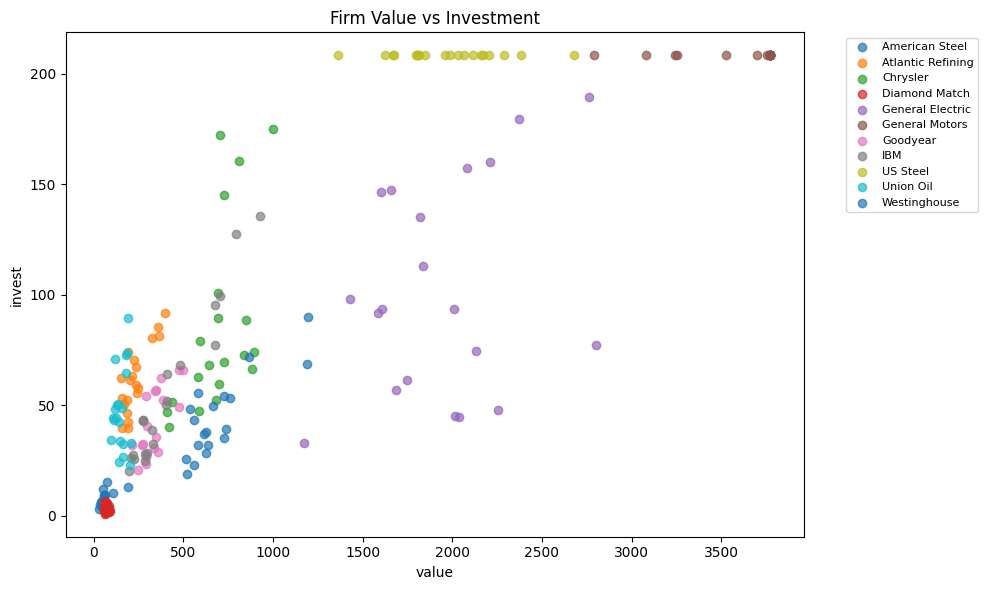

In [12]:

plt.figure(figsize=(10, 6))
for firm, group in df_clean.groupby("firm"):
    plt.scatter(group["value"], group["invest"], label=firm, alpha=0.7)

plt.title("Firm Value vs Investment")
plt.xlabel("value")
plt.ylabel("invest")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()


**Main takeaway:** Firms with higher market value generally tend to have higher investment, although the relationship is not identical across firms.

## Visualization 2: Line chart
Line chart of average investment by year.

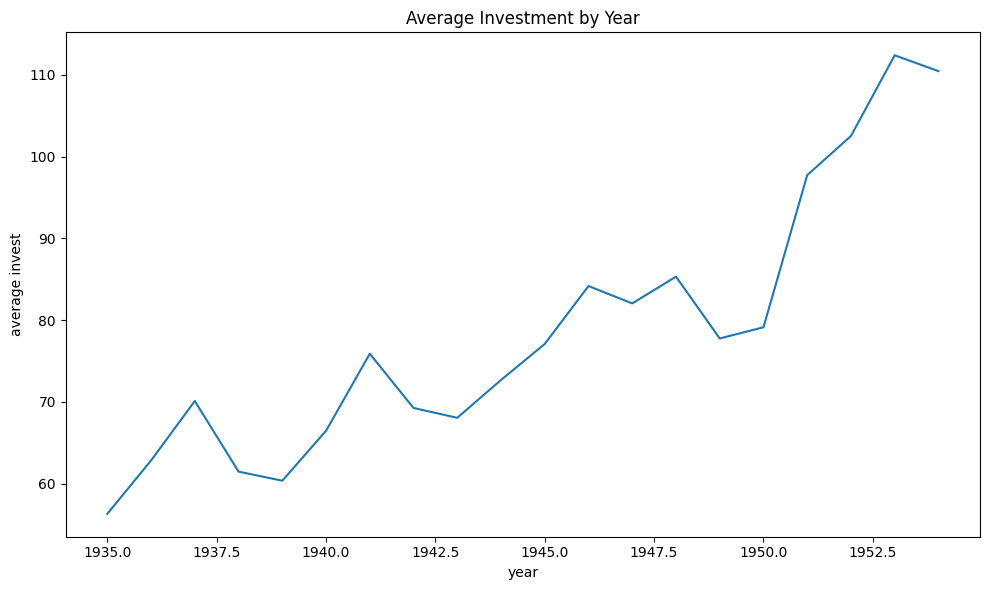

In [13]:

plt.figure(figsize=(10, 6))
avg_invest_by_year.plot()
plt.title("Average Investment by Year")
plt.xlabel("year")
plt.ylabel("average invest")
plt.tight_layout()
plt.show()


**Main takeaway:** Average investment changes across time rather than remaining flat, which shows that the dataset has a meaningful time trend.

## Visualization 3: Box plot
Box plot of investment for the 6 firms with the highest average investment.

<Figure size 1000x600 with 0 Axes>

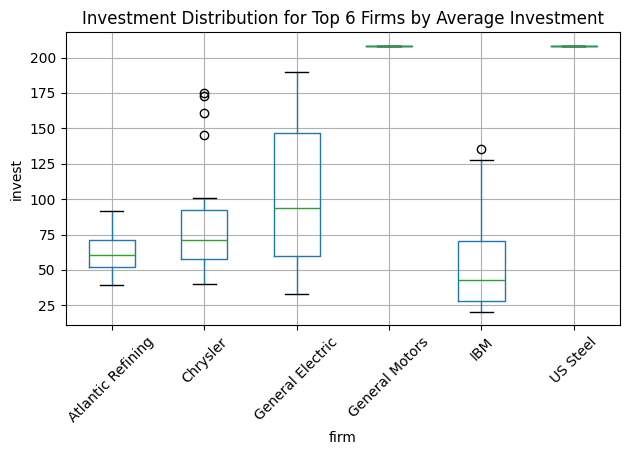

In [14]:

top_firms = df_clean.groupby("firm")["invest"].mean().sort_values(ascending=False).head(6).index
box_df = df_clean[df_clean["firm"].isin(top_firms)]

plt.figure(figsize=(10, 6))
box_df.boxplot(column="invest", by="firm", rot=45)
plt.title("Investment Distribution for Top 6 Firms by Average Investment")
plt.suptitle("")
plt.xlabel("firm")
plt.ylabel("invest")
plt.tight_layout()
plt.show()


**Main takeaway:** The spread of investment differs by firm, and some firms have both higher medians and wider variation than others.

## Visualization 4: Histogram
Histogram of `capital`.

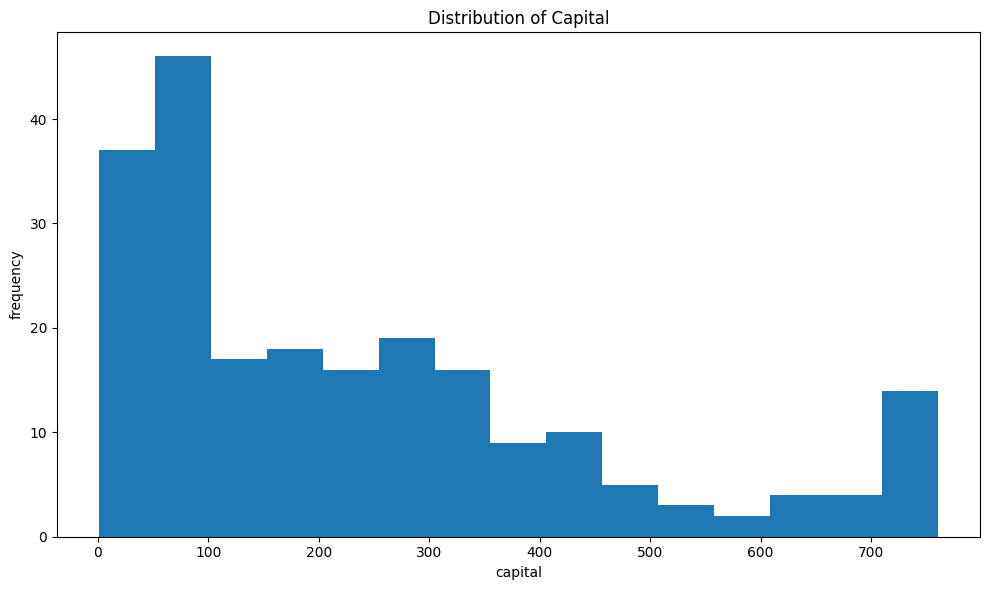

In [15]:

plt.figure(figsize=(10, 6))
plt.hist(df_clean["capital"], bins=15)
plt.title("Distribution of Capital")
plt.xlabel("capital")
plt.ylabel("frequency")
plt.tight_layout()
plt.show()


**Main takeaway:** Capital is not uniformly distributed; observations cluster in lower-to-middle ranges with a longer right tail.

## Visualization 5: Heatmap
Heatmap of correlations among the numeric columns.

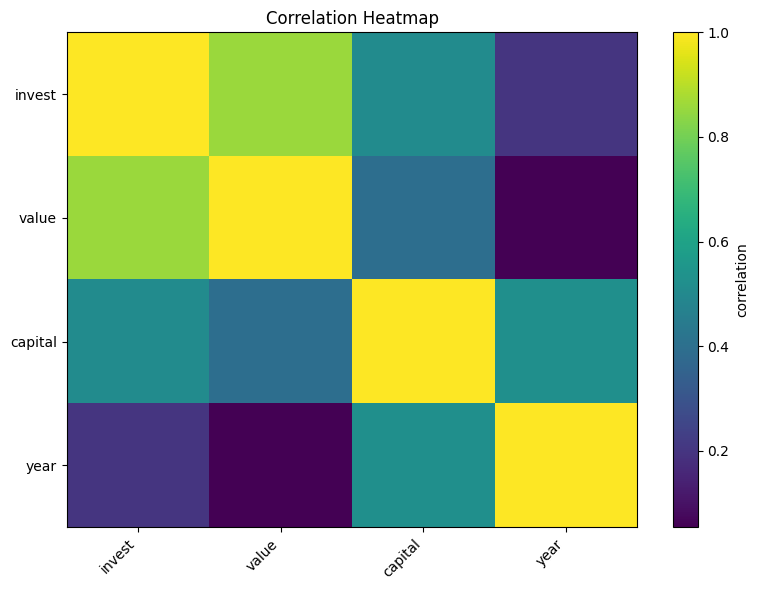

In [16]:

corr = df_clean[["invest", "value", "capital", "year"]].corr()

plt.figure(figsize=(8, 6))
plt.imshow(corr, aspect="auto")
plt.colorbar(label="correlation")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=45, ha="right")
plt.yticks(range(len(corr.index)), corr.index)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


**Main takeaway:** The numeric variables are positively related overall, with investment most strongly associated with firm value and capital.